# Explore models of gut-immune models and their optimal solutions
## The general model
We consider a model for a microbe $G_\mu$ that enters the gut at rate $b_\mu$, grows in the gut by exploiting niche(s), $n_\alpha$, and depleting that niche at rate $s_{\alpha,\mu}$, subject to pressure from the immune system $X_\mu$:
\begin{align}
\dot{G}_\mu = \left[\sum_\alpha \left(n_\alpha - \sum_\nu s_{\nu,\alpha} G_\nu\right) - X_\mu\right]G_\mu + b_\mu,
\end{align}
with immune pressure $X_\mu(\lambda,w)$ mediated by inflammatory cells ($\lambda$) and tolerant cells ($w$).

## The case of no ecological interations
In the case where there are no cross species interactions (so that each species can be thought of as exploiting a single niche), the equation simplifies to 
\begin{align}
\dot{G}_\mu = \left[n_\mu - s_\mu G_\mu - X_\mu \right]G_\mu + b_\mu,
\end{align}
and the steady-state solution for this system is:
\begin{align}
\tilde{G_\mu} = \frac{\frac{n_\mu -X_\mu}{s_\mu} + \left[\left(\frac{n_\mu -X_\mu}{s_\mu}\right)^2 + 4\frac{b_\mu}{s_\mu} \right]^{\frac{1}{2}}}{2}.
\end{align}

We assuming that upon establishment the microbe causes harm to the host organism at rate $h_\mu$, and further that the long-term immune response to the microbe is slower than the establishment time of the microbe. We seek the solution to the optimization problem
\begin{align}
\min_{\lambda \geq 0,w \geq 0}\left\{ h_\mu G_\mu + \sum_k \beta_k F_k(\lambda, w) \right\},
\end{align}
where second term corresponds to additional costs from mounting an immune response, and $\beta \geq 0$ is a parameter. This function can be tailored to impose many desired biological constraints.

### One microbe, one receptor
As a starting point, we will take, $F(\lambda) = \lambda$, and define the lagrangian in terms of $X_\mu$
\begin{align}
L(\lambda, \delta) =  h_\mu G_\mu + \beta \lambda + \delta\cdot (l^2 - \lambda),
\end{align}
where we have introduced a slack variable, $l \in \mathbb{R}$, and lagrange multiplier, $\delta \in \mathbb{R}$.

Solving the KKT conditions, the optimal solution can be shown to be
\begin{align}
\tilde{\lambda}(\beta) = 
\begin{cases}
0, ~ \beta \geq \frac{\sigma h}{2s}\frac{n}{\left[n^2 + 4bs \right]^{\frac{1}{2}}} + \frac{\sigma h}{2s}\\
\frac{n}{\sigma} - \left(\beta -\frac{\sigma h}{2s}\right) \frac{s}{\sigma}\left[\frac{ 4\frac{b}{s}}{\beta\left|\frac{\sigma h}{s} -\beta\right|}\right]^{\frac{1}{2}}, ~\text{otherwise}.
\end{cases}
\end{align}

In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import patheffects
import scipy.optimize
from scipy.optimize import minimize, LinearConstraint, Bounds, NonlinearConstraint, linprog
from math import erf
import multiprocessing as mp
# from tqdm import tqdm
from joblib import Parallel, delayed
import itertools
import os
import time
# import mpltern
# from mpltern.datasets import get_triangular_grid
import pandas as pd
import plotly.graph_objects as go

plt.style.use('/Users/ObinnaUkogu/Desktop/custom.mplstyle')
%config InlineBackend.figure_format = 'retina'

In [2]:
# Define parameters
gam = 1 # Immune pressure per inflammatory cell
n = 1 # Niche supply
s = 10 # Niche depletion rate per microbe
b = 0.1*s # Immigration rate
h = 1 # Harmfulness of microbe
sigma = np.eye(2)

rng = 50
pnts = 100

In [3]:
# Define functions
def X(l,w, Sigma = 1): # Immune-pressure
    # if rec_num == 1:
    #     out = gam*l**2/(l + w)
    # else:
    out = sigma.dot(l)/(1 + sigma.dot(w))
    return out

def G(l,w): # Microbe steady state population
    out = (n-X(l,w))/(2*s) + np.sqrt((n-X(l,w))**2/s**2 + 4*b/s)/2
    return out

def GofX(X, h = h, b = b, s = s, n = n): # Microbe steady state population
    out = (n-X)/(2*s) + np.sqrt((n-X)**2/s**2 + 4*b/s)/2
    return out

def dGofX(X): # Microbe steady state population
    out = -(1 + (n - X)/np.sqrt((n-X)**2 + 4*b*s))/(2*s)
    return out

def net_harm(X, h = h, b = b, s = s, n = n):
    out = np.sum(h*GofX(X, h = h, b = b, s = s, n = n))
    return out

def objective(x, model = "one_m_one_r", beta = 1.0, sigma = 1, h = h, b = b, s = s, n = n): # Cost function
    # beta := Cost of immune pressure
    
    if model == "one_m_one_r":
        out = net_harm(sigma*x, h = h, b = b, s = s, n = n) + beta*x
    elif model == "two_m_two_r":
        out = net_harm(sigma.dot(x), h = h, b = b, s = s, n = n) + beta*np.sum(x)
    elif model == "effective inflammation":
        l, w = x[0:int(len(x)/2)], x[int(len(x)/2):]
        out = net_harm(l,w) + beta*np.sum(G(l,w)*X(l,w))
    return out

### (A) Check analytic solution for one microbe and one receptor

In [4]:
# Define analytic solution
def one_m_one_r(beta, sigma = 1, h = h, b = b, s = s, n = n):
    if beta < sigma*h/(2*s)*n/np.sqrt(n**2 + 4*b*s) + sigma*h/(2*s):
        out = n/sigma - (2/sigma)*(beta - sigma*h/(2*s))*np.sqrt(b*s)/np.sqrt(beta*(sigma*h/s - beta))
    else:
        out = 0.0

    return out

We show perfect agreement with the solution from numerical optimization.

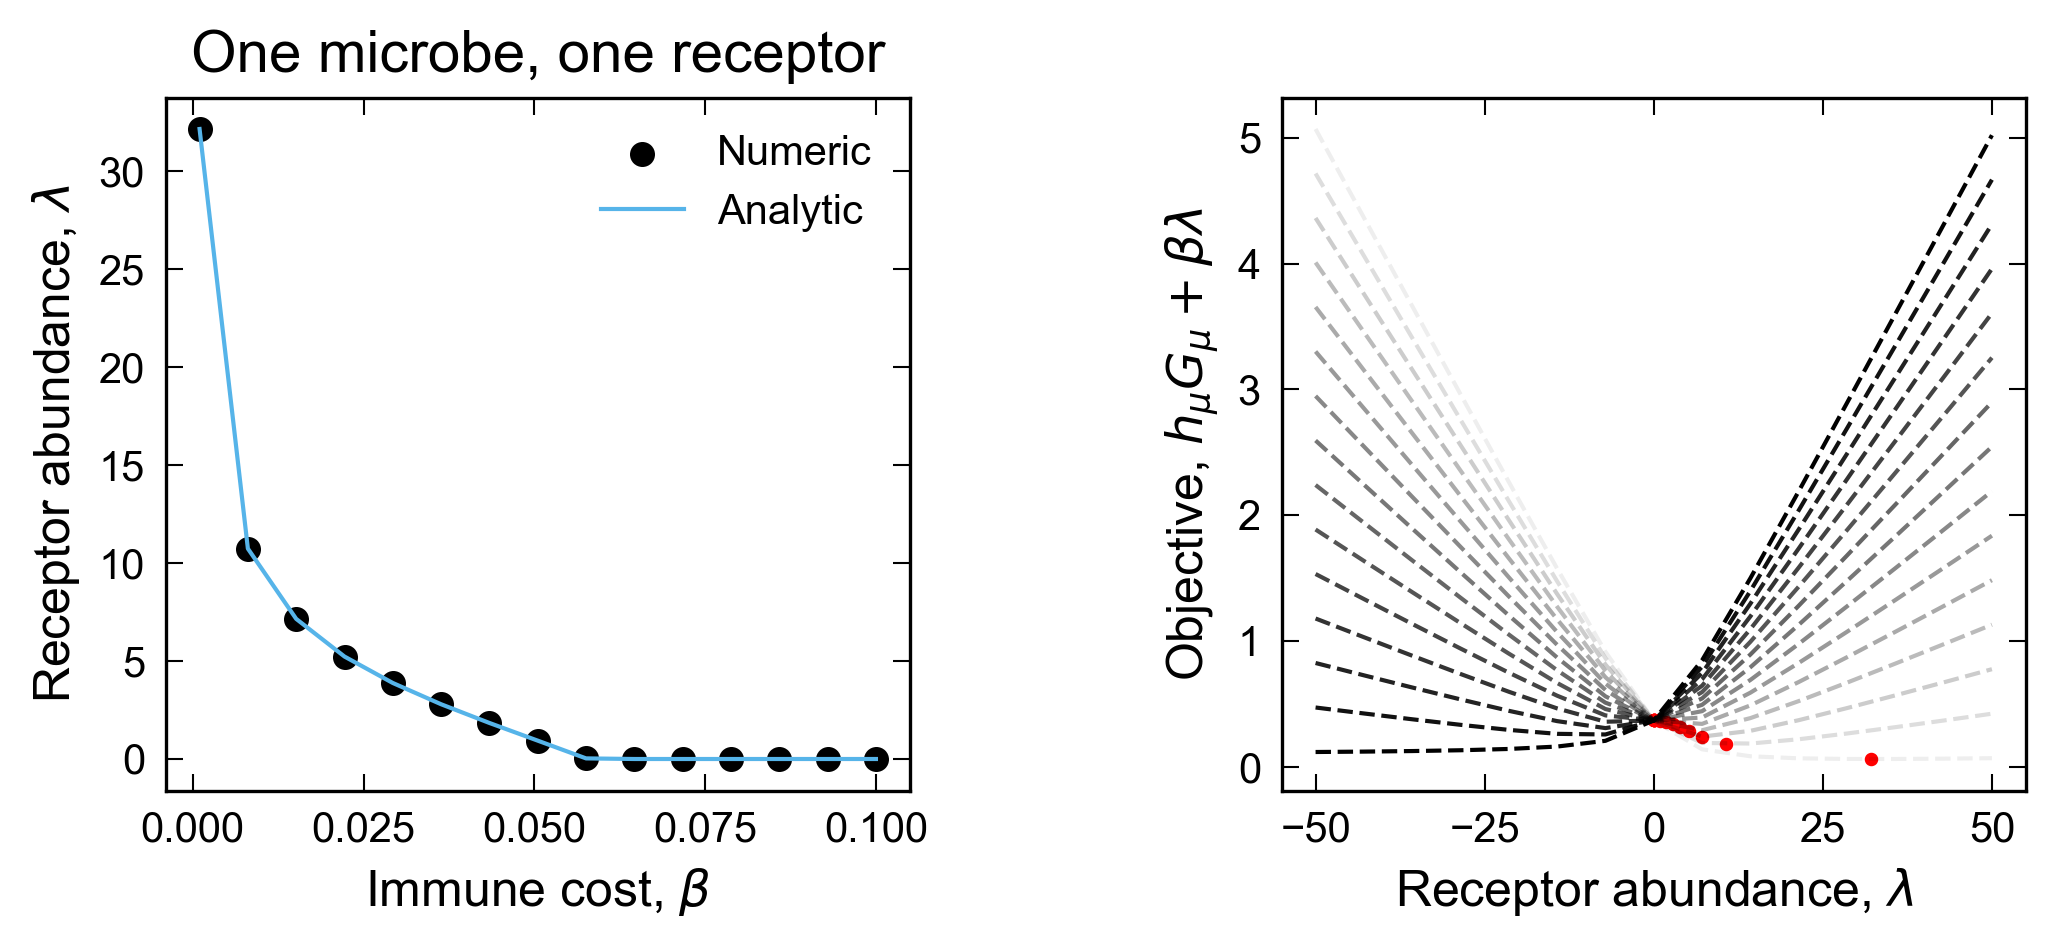

In [5]:
# Plot numerical values and analytic values verus beta
fig, (ax1, ax2) = plt.subplots(1, 2, dpi = 150, figsize=(8, 3))

constr1 = LinearConstraint([1.0], 0.0)
betas = np.linspace(0.01*h/s, h/s, 15)
ls = np.linspace(-rng, rng, 15)
for i, p in enumerate(betas):

    res = minimize(objective, args = ("one_m_one_r", p),
             x0 = [rng/2],
             tol=1e-8,
             constraints = [constr1])
    p_jittered = np.random.normal(p, 0.05)
    ax1.scatter(p, res.x, c= 'black', label = "Numeric" if i == 0 else '')
    ax2.plot(ls, np.array([objective(j, model = "one_m_one_r", beta = p) for j in ls]), 'k--', alpha = (i + 1)/len(betas))
    ax2.scatter(res.x, objective(res.x, model = "one_m_one_r", beta = p), color = 'red', s = 5)

ax1.plot(betas, np.array([one_m_one_r(j) for j in betas]), label = "Analytic")
    
#ax.axvline(x = h/s, color = 'k', linestyle = '--', label = r'$\beta = \frac{h}{s}$')
ax1.title.set_text(r'One microbe, one receptor')

ax1.set(ylabel=r'Receptor abundance, $\lambda$',xlabel=r'Immune cost, $\beta$')
ax1.minorticks_off()
ax1.legend()
ax2.set(xlabel=r'Receptor abundance, $\lambda$',ylabel=r'Objective, $h_\mu G_\mu + \beta \lambda$')
ax2.minorticks_off()
fig.subplots_adjust(wspace=0.50, hspace=0.0)

### (B) Check receptor co-existence conditions for two microbes and two receptors
Given two microbes $G_1$ and $G_2$ and two receptors $\lambda_1$ and $\lambda_2$, the affinity of receptor $k$ for microbe $mu$ is given by the matrix
\begin{equation}
\Sigma = [\sigma]_{\mu,k}.
\end{equation}
We assume the microbes are alike in every other respect, except potentially in their harmfulness, $h_\mu$.

In the case of two harmful microbes, we derived the following conditions for the two receptors to co-exist in the optimal repertoire. First, no single receptor is more avid than the other for both microbes,
\begin{equation}
    \sigma_{2,2} > \sigma_{2,1}, \sigma_{1,1} > \sigma_{1,2}~~\text{or}~~\sigma_{2,2} < \sigma_{2,1}, \sigma_{1,1} < \sigma_{1,2}.
\end{equation}

In [40]:
# Plot numerical values and analytic values verus beta
constr1 = LinearConstraint([1.0,0.0], 0.0)
constr2 = LinearConstraint([0.0,1.0], 0.0)
sigma_1 = np.array([1.0, 0]) # row 1 of Sigma
sigma_2 = np.vstack([np.linspace(0.0, 1.0, 25), np.ones(25)]).T # row 2 of Sigma
lam_opts_harm = []
obj_opts_harm = []
X_opts_harm = []
lam_opts_mixed = []
obj_opts_mixed = []

for i, p in enumerate(sigma_2):
    Sigma = np.vstack([sigma_1, p])
    # Two harmful microbes
    res_harm = minimize(objective, args = ("two_m_two_r", 0.01*h/s, Sigma.T),
             x0 = [rng/2,rng/2],
             tol=1e-9,
             constraints = [constr1, constr2])
    lam_opts_harm.append(res_harm.x)
    obj_opts_harm.append(res_harm.fun)
    X = Sigma.dot(res_harm.x)
    X_opts_harm.append(np.array([(X[0]/X[1] > sigma_1[1]/p[1])*(X[0]/X[1] < sigma_1[0]/p[0]),
                                 (X[0]/X[1] < sigma_1[1]/p[1])*(X[0]/X[1] > sigma_1[0]/p[0])]))
    
    # One harmful and one beneficial
    res_mixed = minimize(objective, args = ("two_m_two_r", 0.01*h/s, Sigma.T, np.array([1,-1])),
             x0 = [rng/2,rng/2],
             tol=1e-8,
             constraints = [constr1, constr2])
    lam_opts_mixed.append(res_mixed.x)
    obj_opts_mixed.append(res_mixed.fun)

lam_opts_harm_arr = np.vstack(lam_opts_harm)
obj_opts_harm_arr = np.vstack(obj_opts_harm)
X_opts_harm_arr = np.vstack(X_opts_harm)
lam_opts_mixed_arr = np.vstack(lam_opts_mixed)
obj_opts_mixed_arr = np.vstack(obj_opts_mixed)

/var/folders/_q/50__mrnj2zv6hb8crhk3q46m0000gn/T/ipykernel_97478/208951435.py:22: RuntimeWarning:

divide by zero encountered in scalar divide

/var/folders/_q/50__mrnj2zv6hb8crhk3q46m0000gn/T/ipykernel_97478/208951435.py:23: RuntimeWarning:

divide by zero encountered in scalar divide



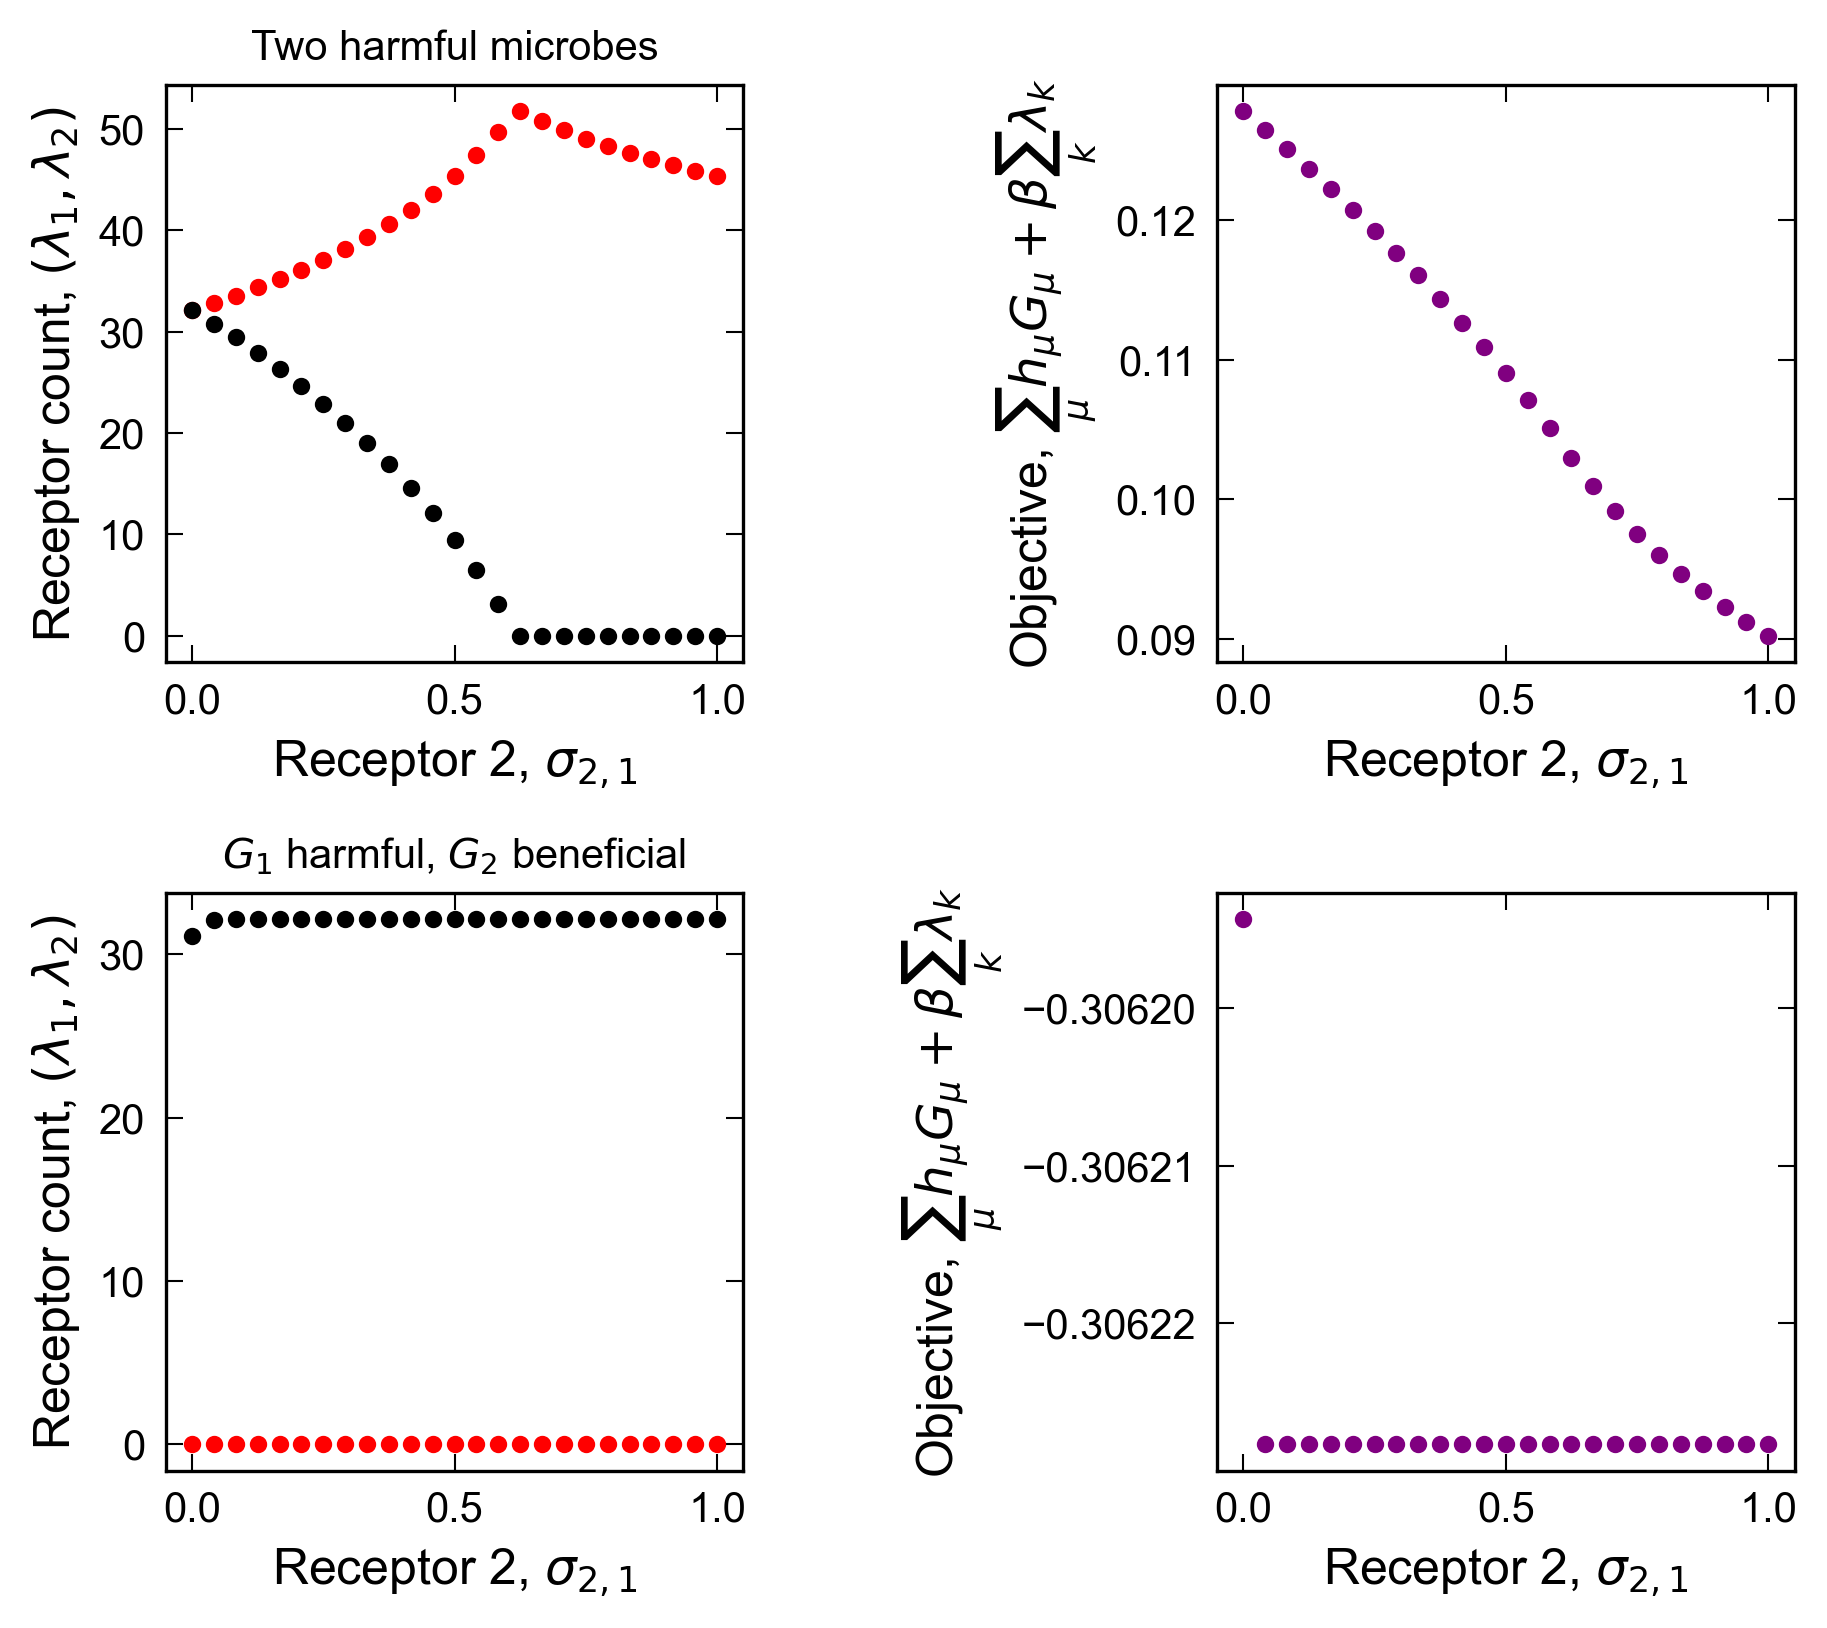

In [41]:
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, dpi = 150, figsize=(8, 6))
size = 10

im1 = ax1.scatter(sigma_2[:,0], (lam_opts_harm_arr[:,1]), # /(lam_opts_harm_arr[:,0] + lam_opts_harm_arr[:,1]),
                 color = 'red',
                 s = size)
ax1.scatter(sigma_2[:,0], (lam_opts_harm_arr[:,0]), # /(lam_opts_harm_arr[:,0] + lam_opts_harm_arr[:,1]),
                 color = 'black',
                 s = size)

im2 = ax2.scatter(sigma_2[:,0], obj_opts_harm_arr,
             color = 'purple',
             s = size)

im3 = ax3.scatter(sigma_2[:,0], (lam_opts_mixed_arr[:,1]), #/(lam_opts_mixed_arr[:,0] + lam_opts_mixed_arr[:,1]),
                 color = 'red',
                 s = size)
ax3.scatter(sigma_2[:,0], (lam_opts_mixed_arr[:,0]), #/(lam_opts_mixed_arr[:,0] + lam_opts_mixed_arr[:,1]),
                 color = 'black',
                 s = size)

im4 = ax4.scatter(sigma_2[:,0], obj_opts_mixed_arr,
             color = 'purple',
             s = size)
    
ax1.set_title(r'Two harmful microbes', fontsize = 10)
ax1.set(xlabel=r'Receptor 1, $\sigma_{2,1}$',ylabel=r'Receptor count, $(\lambda_1, \lambda_2)$')
ax1.minorticks_off()
ax1.set_box_aspect(1)

ax2.set(xlabel=r'Receptor 1, $\sigma_{2,1}$',ylabel=r'Objective, $\sum_\mu h_\mu G_\mu + \beta \sum_k\lambda_k$')
ax2.minorticks_off()
ax2.set_box_aspect(1)

ax3.set_title(r'$G_1$ harmful, $G_2$ beneficial', fontsize = 10)
ax3.set(xlabel=r'Receptor 1, $\sigma_{2,1}$',ylabel=r'Receptor count, $(\lambda_1, \lambda_2)$')
ax3.minorticks_off()
ax3.set_box_aspect(1)

ax4.set(xlabel=r'Receptor 1, $\sigma_{2,1}$',ylabel=r'Objective, $\sum_\mu h_\mu G_\mu + \beta \sum_k\lambda_k$')
ax4.minorticks_off()
ax4.set_box_aspect(1)

fig.subplots_adjust(wspace=0.3, hspace=.4)

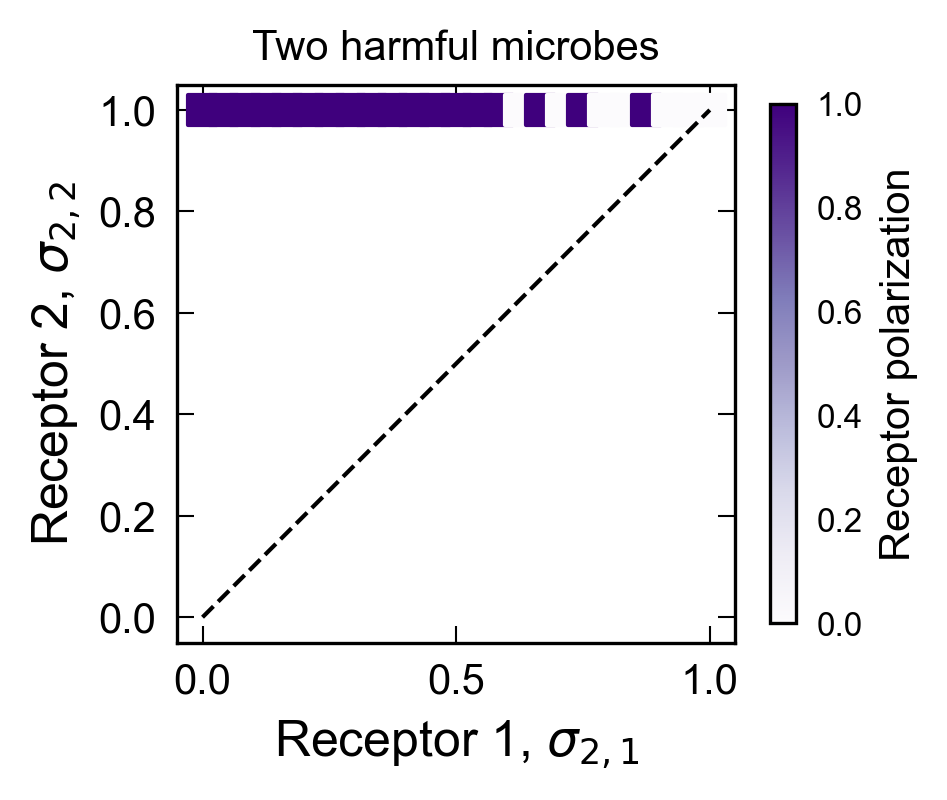

In [34]:
# Show that conditions are satisfied
fig, ax1 = plt.subplots(1, 1, dpi = 150, figsize=(3, 3))
size = 50

im1 = ax1.scatter(sigma_2[:,0], sigma_2[:,1],
                 c = (X_opts_harm_arr[:,0] + X_opts_harm_arr[:,1])*(sigma_2[:,0] < sigma_2[:,1]),
                 cmap = 'Purples', marker = 's', norm = mpl.colors.Normalize(vmin = 0, vmax = 1),
                 s = size)

ax1.plot(np.linspace(0,1, 10), np.linspace(0,1, 10), 'k--')

ax1.set_title(r'Two harmful microbes', fontsize = 10)
cb1 = fig.colorbar(im1, ax=ax1, orientation='vertical', shrink = 0.75, pad = 0.05)
cb1.set_label("Receptor polarization", fontsize = 10)
cb1.ax.tick_params(labelsize=8)
ax1.set(xlabel=r'Receptor 1, $\sigma_{2,1}$',ylabel=r'Receptor 2, $\sigma_{2,2}$')
ax1.minorticks_off()
ax1.set_box_aspect(1)

Discuss convexity of the objective function

In [8]:
# Visualize cost landscape
pnts = 50
lvec = np.linspace(0.0, 25, pnts)

ls = np.array(list(itertools.product(lvec.tolist(),lvec.tolist())))
l1, l2 = np.meshgrid(lvec, lvec)
z = np.array([objective(q, "two_m_two_r", 0.1*h/s, 
                        np.vstack([np.array([3/4, 1/2]), np.array([1/2, 3/4])])) for q in ls]).reshape(pnts,pnts)


fig = go.Figure(data=[go.Surface(z=z, x=l1, y=l2)])
fig.update_traces(contours_z=dict(show=True, usecolormap=True,
                                  highlightcolor="limegreen", project_z=True))
fig.update_layout(title='Cost function - two harmful', autosize=False,
                  scene_camera_eye=dict(x=1.87, y=0.88, z=-0.64),
                  width=500, height=500,
                  margin=dict(l=65, r=50, b=65, t=90))

# Update the layout
fig.update_layout(scene=dict(
    xaxis_title=r'Receptor 1',
    yaxis_title=r'Receptor 2',
    zaxis_title=r'Objective'
))

fig.show()

In [9]:
# Visualize cost landscape
pnts = 50
lvec = np.linspace(0.0, 20, pnts)

ls = np.array(list(itertools.product(lvec.tolist(),lvec.tolist())))
l1, l2 = np.meshgrid(lvec, lvec)
z = np.array([objective(q, "two_m_two_r", 0.1*h/s, 
                        np.vstack([np.array([3/4, 1/2]), np.array([1/2, 3/4])]), np.array([1,-1])) for q in ls]).reshape(pnts,pnts)


fig = go.Figure(data=[go.Surface(z=z, x=l1, y=l2)])
fig.update_traces(contours_z=dict(show=True, usecolormap=True,
                                  highlightcolor="limegreen", project_z=True))
fig.update_layout(title='Cost function - one harmful, one beneficial', autosize=False,
                  scene_camera_eye=dict(x=1.87, y=0.88, z=-0.64),
                  width=500, height=500,
                  margin=dict(l=65, r=50, b=65, t=90))

# Update the layout
fig.update_layout(scene=dict(
    xaxis_title=r'Receptor 1',
    yaxis_title=r'Receptor 2',
    zaxis_title=r'Objective'
))

fig.show()

### (B) Try a different immune cost function: $F(\lambda, w) = \lambda$
In this case, it can be shown that the optimal solution is
\begin{align}
\gamma\tilde{\lambda} &= \max\left\{0,n - s\frac{2\left(\beta -\frac{h}{2s}\right) \sqrt{\frac{b}{s}}}{\left[\beta\left(\frac{h}{s} -\beta\right)\right]^{\frac{1}{2}}}\right\}\\
\tilde{w} &= 0.
\end{align}
Thus we observe that this objective "regularizes" the solution, but leads to tolerance being unused, as expected.

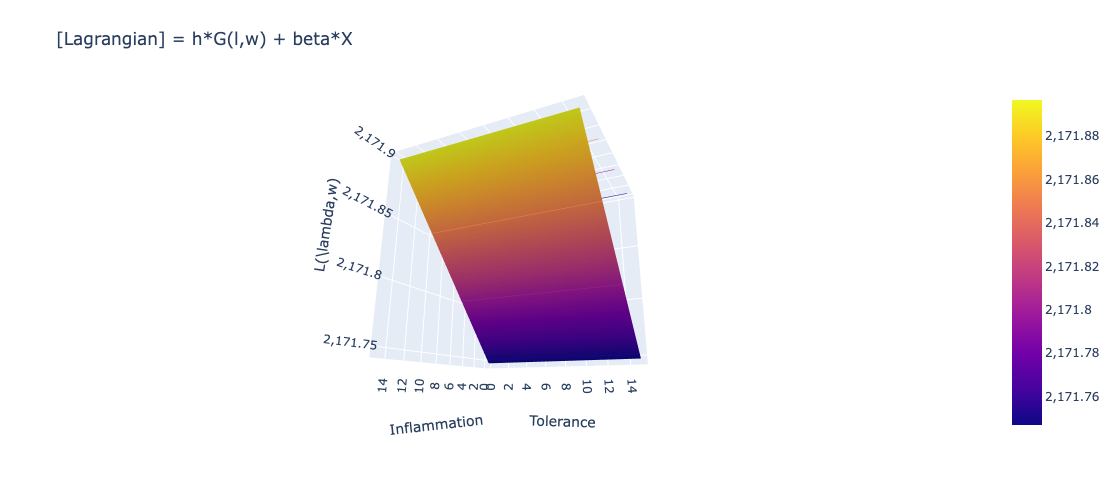

In [13]:
# Visualize cost landscape
rng = 15
pnts = 100
lvec = np.linspace(0.01, rng, pnts)
wvec = np.linspace(0.01, rng, pnts)

l, w = np.meshgrid(lvec, wvec)
z = net_harm(l,w) + (0.1*h/s)*l


fig = go.Figure(data=[go.Surface(z=z, x=l, y=w)])
fig.update_traces(contours_z=dict(show=True, usecolormap=True,
                                  highlightcolor="limegreen", project_z=True))
fig.update_layout(title='[Lagrangian] = h*G(l,w) + beta*X', autosize=False,
                  scene_camera_eye=dict(x=1.87, y=0.88, z=-0.64),
                  width=500, height=500,
                  margin=dict(l=65, r=50, b=65, t=90))

# Update the layout
fig.update_layout(scene=dict(
    xaxis_title=r'Inflammation',
    yaxis_title=r'Tolerance',
    zaxis_title=r'L(\lambda,w)'
))

fig.show()

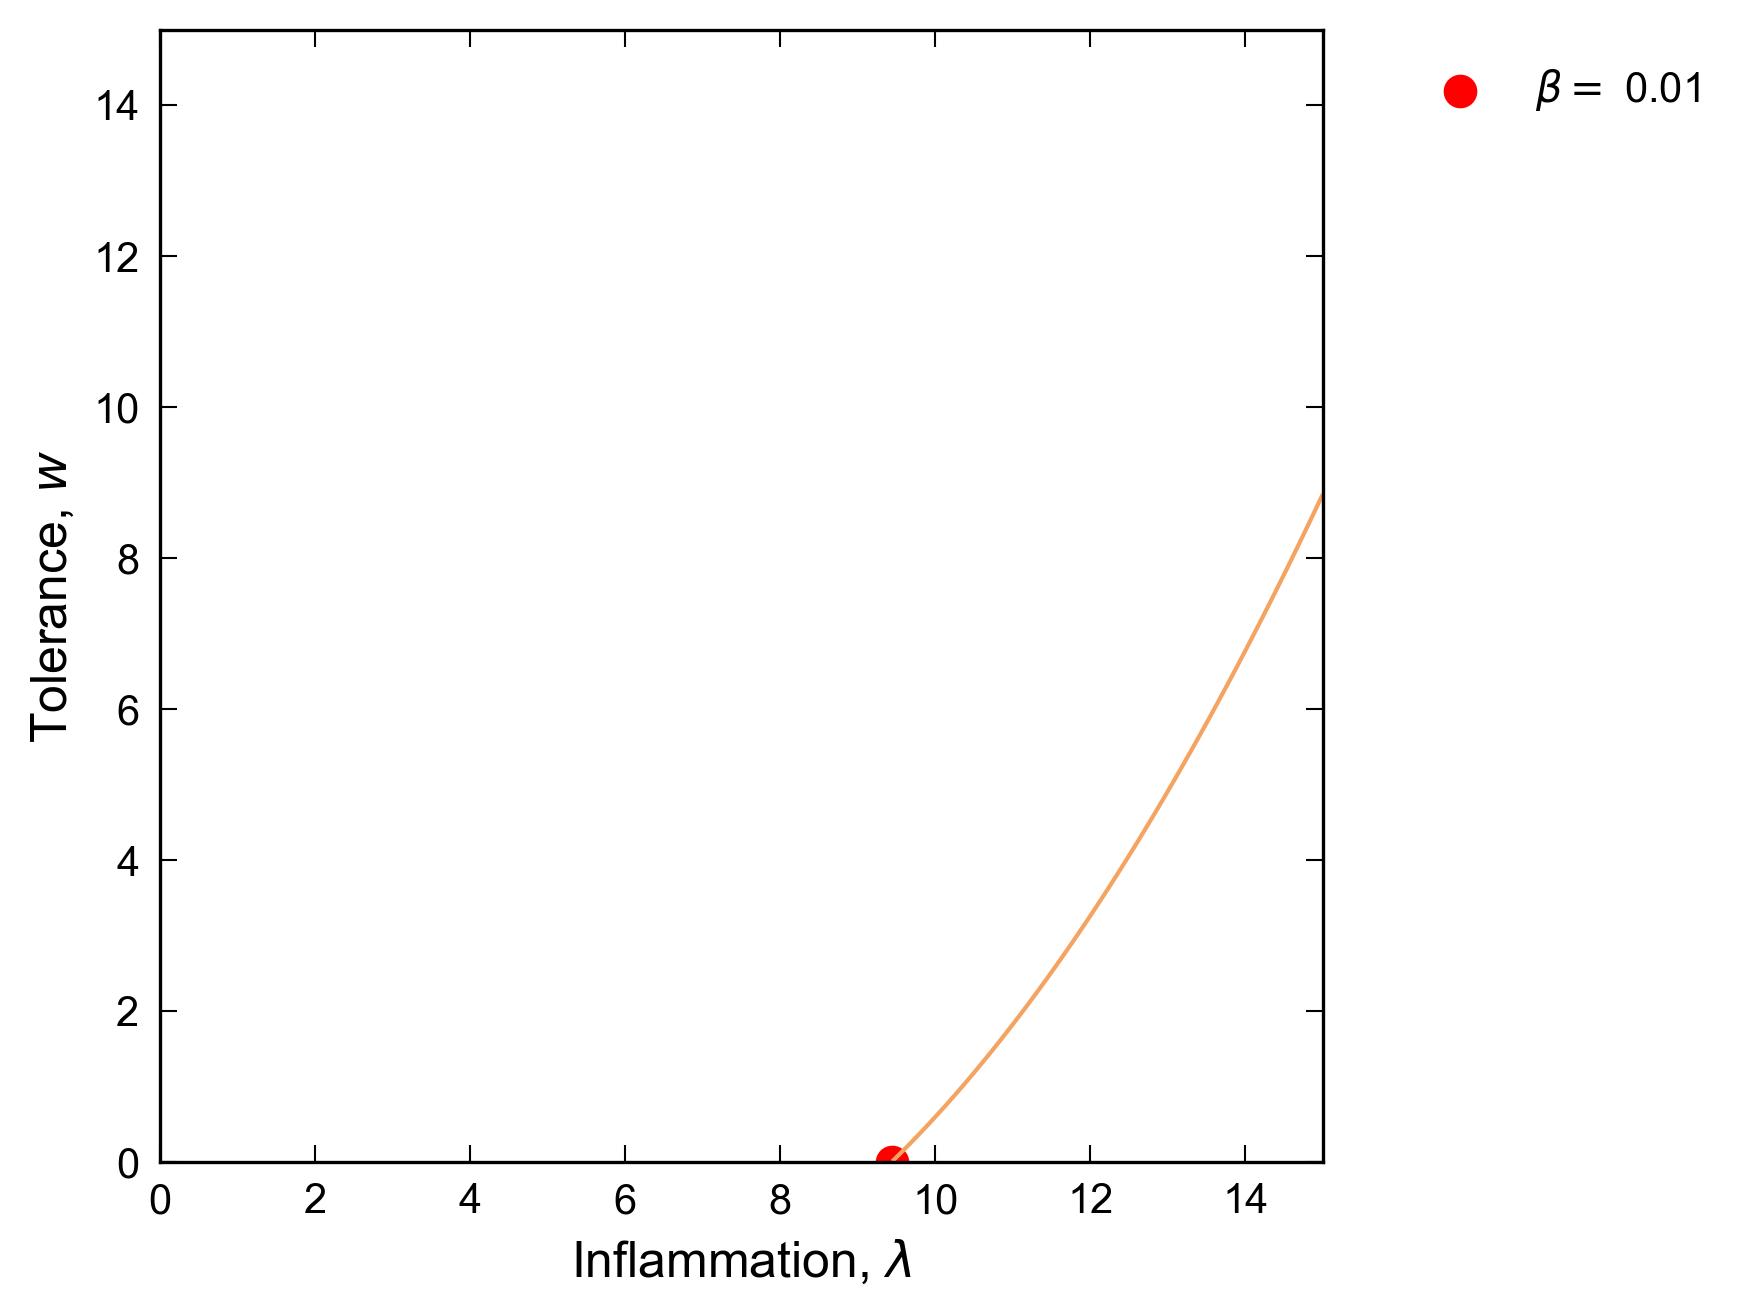

In [14]:
fig, ax = plt.subplots(dpi = 150, figsize=(5, 5))

# Numerically optimize
constr1 = LinearConstraint([1.0,0.0], 0.0)
constr2 = LinearConstraint([0.0,1.0], 0.0)
res_mod_lag = minimize(lagrangian, args = ((0.1*h/s), "inflammatory cells"),
         x0 = np.array([rng,rng]),
         tol=1e-6,
         constraints = [constr1, constr2])

# Evaluate some stuff to plot
obj = net_harm(l,w) + (0.1*h/s)*l
g1 = X(l,w) - X(res_mod_lag.x[0], res_mod_lag.x[1])

cntr = ax.contour(l, w, obj, [0.01, 0.1, 0.5, 1, 2, 4, 8, 16],
                  colors='black')
ax.clabel(cntr, fmt="%2.1f", use_clabeltext=True)
ax.scatter(res_mod_lag.x[0],res_mod_lag.x[1], color = 'red', s = 50, label = r"$\beta=$ "+str((0.1*h/s)))

cg1 = ax.contour(l, w, g1, [0], colors='sandybrown') # Optimal contour from original problem"
#cg1.set(path_effects=[patheffects.withTickedStroke(angle=135)])

ax.set(ylabel=r'Tolerance, $w$',xlabel=r'Inflammation, $\lambda$')
ax.minorticks_off()
ax.legend(bbox_to_anchor=(1.05, 1.0), loc='upper left')

ax.set_xlim(0, rng)
ax.set_ylim(0, rng)

plt.show()

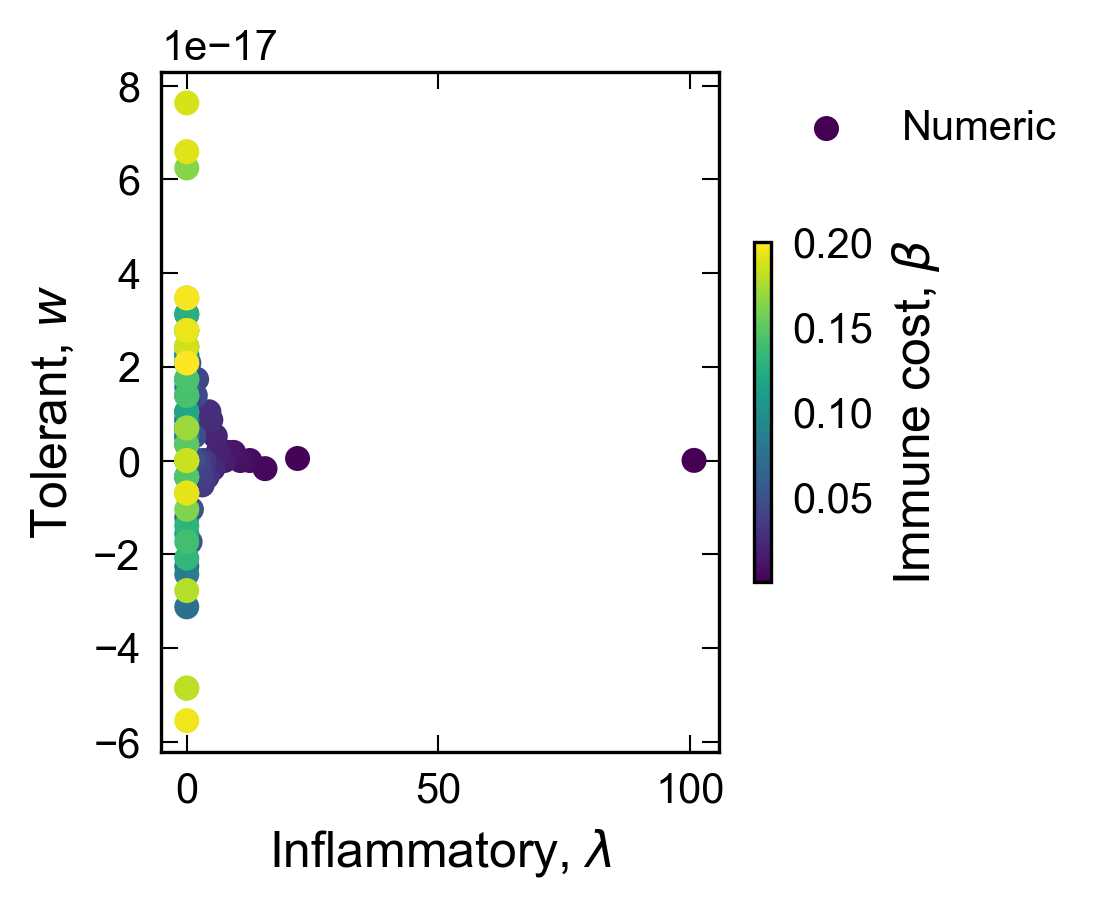

In [15]:
# Plot numerical values and analytic values verus beta
fig, ax = plt.subplots(dpi = 150, figsize=(3, 3))

constr1 = LinearConstraint([1.0,0.0], 0.0)
constr2 = LinearConstraint([0.0,1.0], 0.0)
ls, ws = [], []
betas = np.linspace(0.001*h/s, h/(s) + 0.1, 100)
for i, p in enumerate(betas):

    res = minimize(lagrangian, args = (p, "inflammatory cells"),
             x0 = np.array([rng/2,0/2]),
             tol=1e-8,
             constraints = [constr1, constr2])
    
    ls.append(res.x[0])
    ws.append(res.x[1])

    # ax.scatter(p, X_soln(p), c = 'red', label = "Analytic" if i == 0 else '')
    
# ax.axvline(x = h/s, color = 'k', linestyle = '--', label = r'$\beta = \frac{h}{s}$')

p_jittered = np.random.normal(p, 0.05)
im = ax.scatter(np.array(ls), np.array(ws), c = betas, label = "Numeric")
ax.set(ylabel=r'Tolerant, $w$',xlabel=r'Inflammatory, $\lambda$')
ax.minorticks_off()
ax.legend(bbox_to_anchor=(1.05, 1.0), loc='upper left')
#ax.semilogx()
cb = fig.colorbar(im, ax=ax, shrink = 0.5, pad = 0.05, orientation='vertical')
cb.set_label(r'Immune cost, $\beta$')

Note that the results from numerical optimization are sensitive to where we start the optimization. Sometimes they get stuck on the $\lambda = 0$ boundary.

/var/folders/_q/50__mrnj2zv6hb8crhk3q46m0000gn/T/ipykernel_76366/2663727920.py:3: RuntimeWarning:

divide by zero encountered in divide



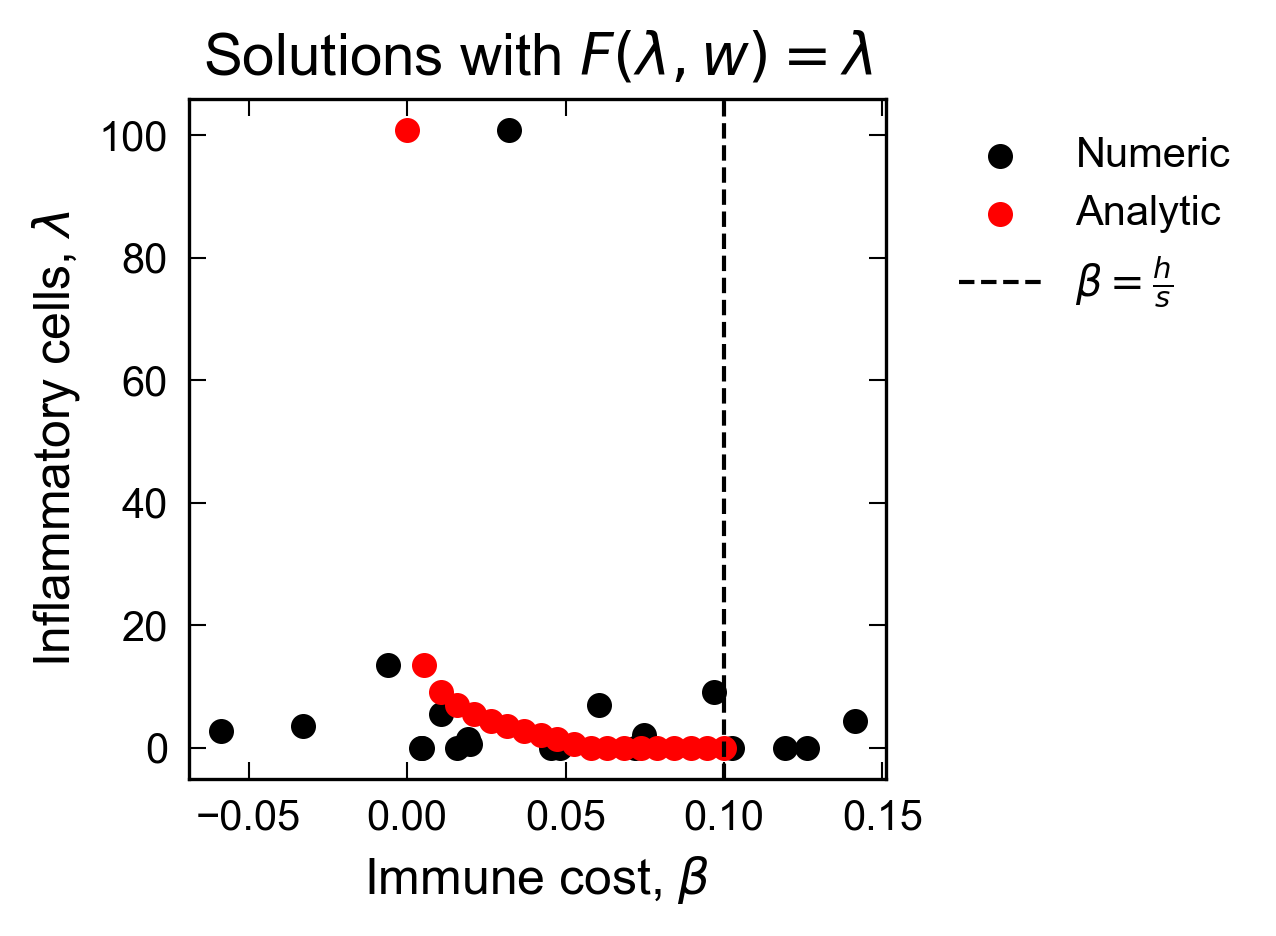

In [16]:
fig, ax = plt.subplots(dpi = 150, figsize=(3, 3))

constr1 = LinearConstraint([1.0,0.0], 0.0)
constr2 = LinearConstraint([0.0,1.0], 0.0)
ls, ws = [], []
betas = np.linspace(0.001*h/s, h/(s), 20)
for i, p in enumerate(betas):

    res = minimize(lagrangian, args = (p, "inflammatory cells"),
             x0 = np.array([rng/2,0.0]),
             tol=1e-8,
             constraints = [constr1, constr2])
    
    ls.append(res.x[0])
    ws.append(res.x[1])

betas_jittered = np.random.normal(betas, 0.05)
ax.scatter(betas_jittered, np.array(ls), c= 'black', label = "Numeric")
ax.scatter(betas, X_soln(betas), c = 'red', label = "Analytic")
ax.title.set_text(r'Solutions with $F(\lambda,w) = \lambda$')
    
ax.axvline(x = h/s, color = 'k', linestyle = '--', label = r'$\beta = \frac{h}{s}$')

ax.set(ylabel=r'Inflammatory cells, $\lambda$',xlabel=r'Immune cost, $\beta$')
ax.minorticks_off()
ax.legend(bbox_to_anchor=(1.05, 1.0), loc='upper left')

### (C) Can we add a term that depends on $w$ to encourage the immune system to use tolerance? Try $F(\lambda,w) = G(\lambda,w)\times X(\lambda,w)$
Such a term probably needs to be a negative cost or benefit. We could also introduce constraints on the magnitude of the inflammatory immune response. In particular a lower bound or equality constraint as was previously proposed. "The inflammatory immune system just can't help itself."

/var/folders/_q/50__mrnj2zv6hb8crhk3q46m0000gn/T/ipykernel_76366/489090350.py:4: RuntimeWarning:

invalid value encountered in divide



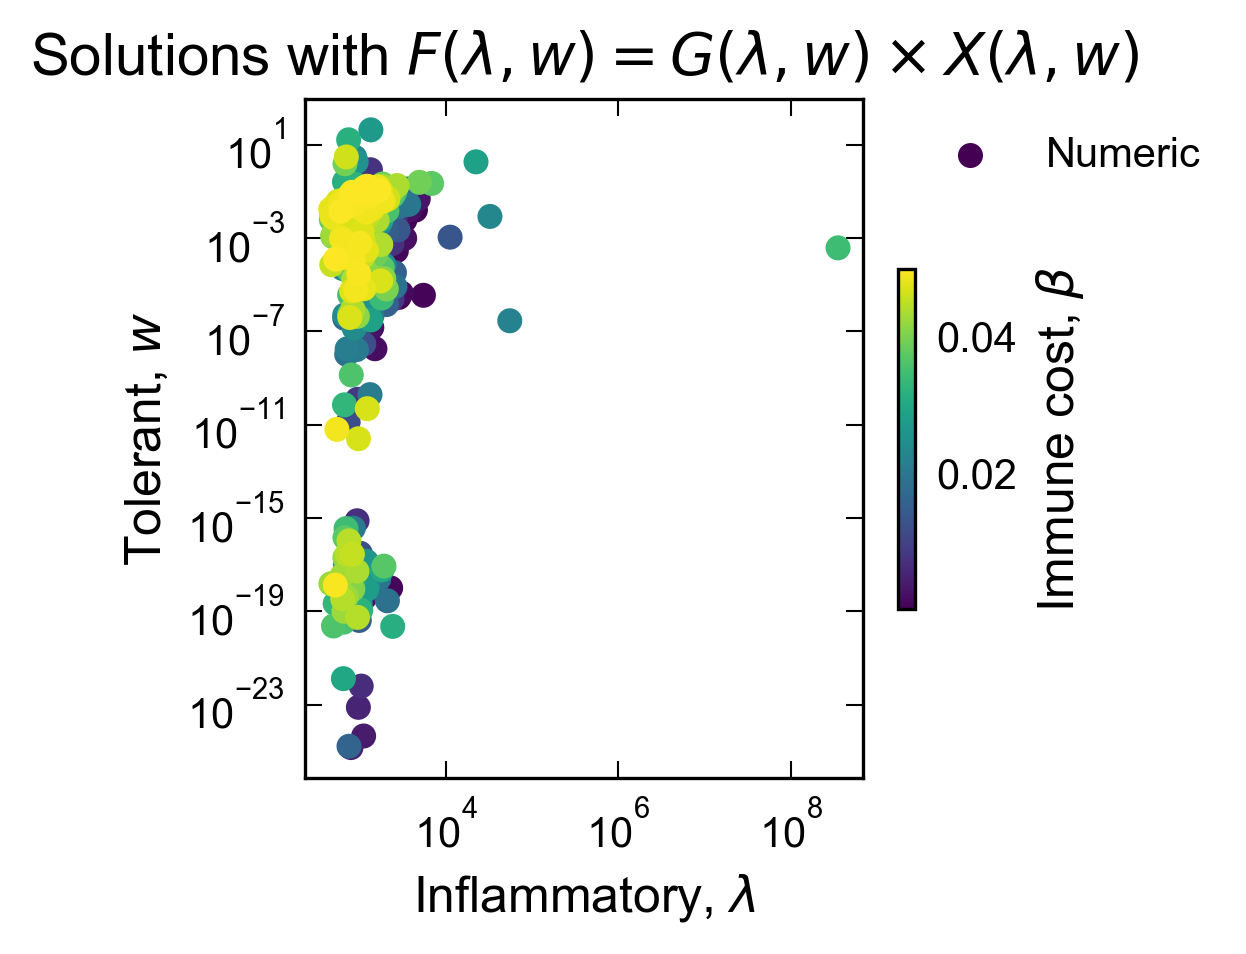

In [17]:
# Plot numerical values and analytic values verus beta
fig, ax = plt.subplots(dpi = 150, figsize=(3, 3))

constr1 = LinearConstraint([1.0,0.0], 0.0)
constr2 = LinearConstraint([0.0,1.0], 0.0)
ls, ws = [], []
betas = np.linspace(0.001*h/s, h/(2*s), 1000)
for i, p in enumerate(betas):

    res = minimize(lagrangian, args = (p, "effective inflammation"),
             x0 = np.array([rng/2,rng/2]),
             tol=1e-9,
             constraints = [constr1, constr2])
    
    ls.append(res.x[0])
    ws.append(res.x[1])

    # ax.scatter(p, X_soln(p), c = 'red', label = "Analytic" if i == 0 else '')
    
# ax.axvline(x = h/s, color = 'k', linestyle = '--', label = r'$\beta = \frac{h}{s}$')

p_jittered = np.random.normal(p, 0.05)
im = ax.scatter(np.array(ls), np.array(ws), c = betas, label = "Numeric")
ax.set(ylabel=r'Tolerant, $w$',xlabel=r'Inflammatory, $\lambda$')
ax.minorticks_off()
ax.title.set_text(r'Solutions with $F(\lambda,w) = G(\lambda,w)\times X(\lambda,w)$')
ax.legend(bbox_to_anchor=(1.05, 1.0), loc='upper left')
ax.semilogx()
ax.semilogy()
cb = fig.colorbar(im, ax=ax, shrink = 0.5, pad = 0.05, orientation='vertical')
cb.set_label(r'Immune cost, $\beta$')

### (D) What is the effect of introducing another microbe to the system?

In [18]:
h = np.array([1,-1])
sigma = np.array([[1, 0], [1, 1]])

In [19]:
# Numerically solve optimization problem
bounds = [(0, None) for i in np.arange(0, 2*len(h))]

ls, ws = [], []
betas = np.logspace(-3, 1, 100)/s
for i, p in enumerate(betas):

    res = minimize(lagrangian, args = (p, "inflammatory cells"),
             x0 = 2*len(h)*[1],
             tol=1e-8,
             bounds = bounds)
    
    ls.append(res.x[0:len(h)].tolist())
    ws.append(res.x[len(h):].tolist())

/var/folders/_q/50__mrnj2zv6hb8crhk3q46m0000gn/T/ipykernel_76366/489090350.py:4: RuntimeWarning:

invalid value encountered in divide



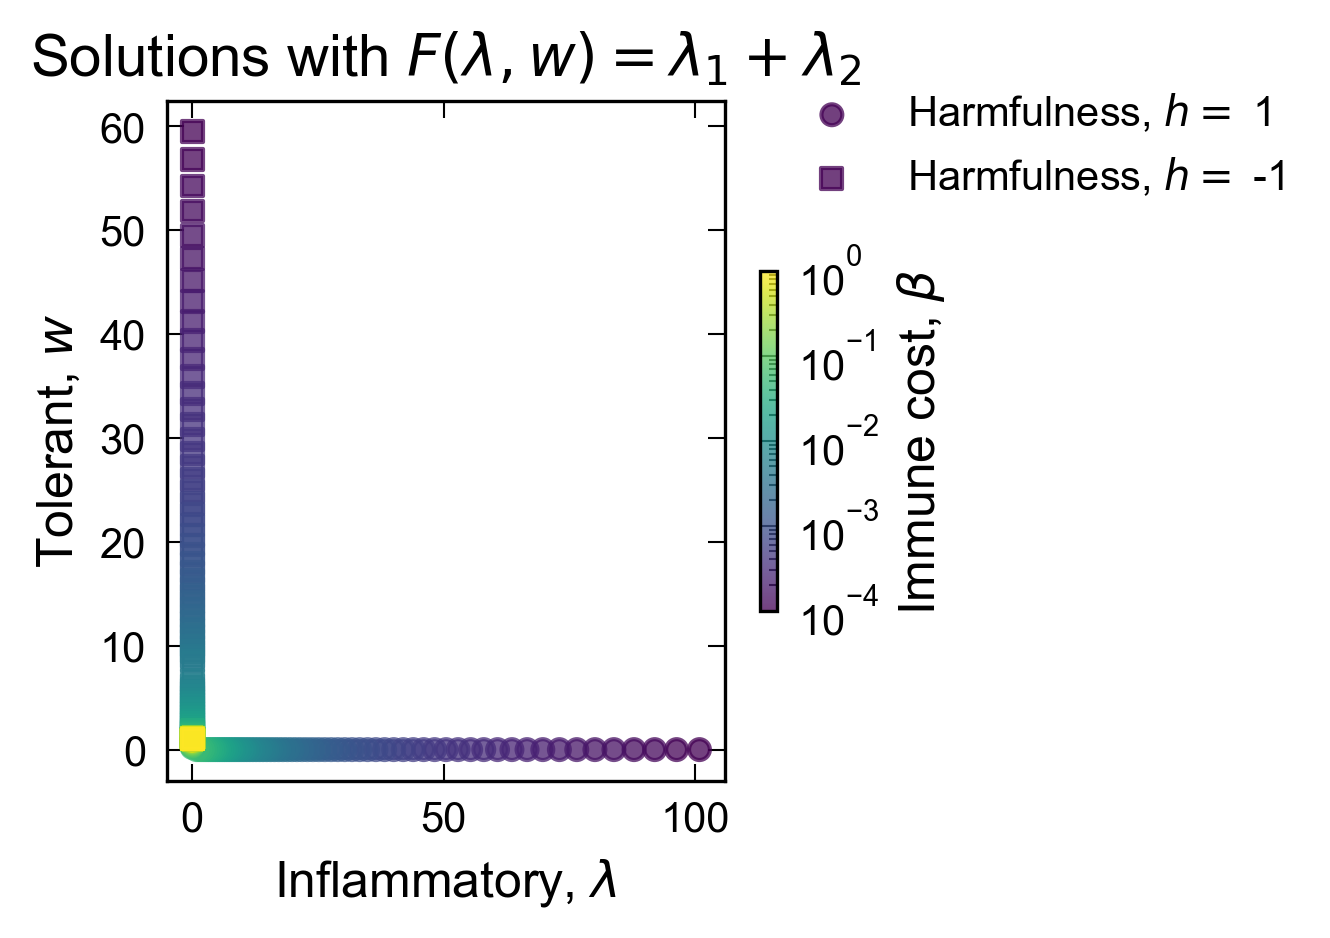

In [20]:
# Plot numerical values and analytic values verus beta
fig, ax = plt.subplots(dpi = 150, figsize=(3, 3))
shapes = ['o', 's']

p_jittered = np.random.normal(p, 0.05)
for i in np.arange(len(h)):
    im = ax.scatter(np.array(ls)[:,i], np.array(ws)[:,i], marker = shapes[i], c = betas, label = r'Harmfulness, $h =$ ' + str(h[i]), alpha = 0.75, norm=mpl.colors.LogNorm())
    
    if i == 0:
        ax.set(ylabel=r'Tolerant, $w$',xlabel=r'Inflammatory, $\lambda$')
        ax.minorticks_off()
        #ax.semilogx()
        cb = fig.colorbar(im, ax=ax, shrink = 0.5, pad = 0.05, orientation='vertical')
        cb.set_label(r'Immune cost, $\beta$')
    ax.legend(bbox_to_anchor=(1.05, 1.07), loc='upper left')
    
ax.title.set_text(r'Solutions with $F(\lambda,w) = \lambda_1 + \lambda_2$')

## The case of one-sided ecological interactions